# Dataset preparation: full expert pass

Audio and speech pair (Hazem and Ebtihal). One notebook: audit, fixes, taxonomy
discovery, annotation package. Derived data lives outside the repo under
`~/workspace/ai-customer-support/dataset/prepared/`.

Contents
1. Setup and input verification
2. Issue audit (13 issues measured)
3. Glossary and normalization findings
4. Deterministic fixes
5. Taxonomy discovery (candidates only)
6. Annotation package
7. Readiness report

Rules: canonical files are read-only and hash-checked. No labels are assigned
to any row. No transcript text in the repo, only counts, file IDs and single
terms. Local only, no uploads.

In [1]:
import json, re, subprocess, sys
from pathlib import Path

import pandas as pd

print("python", sys.version.split()[0])
print("pandas", pd.__version__)
import sklearn
print("sklearn", sklearn.__version__)

WS = Path("/home/hatch/workspace/ai-customer-support")
USER_FILES = Path("/home/hatch/workspace/user/files")
PREPARED = WS / "dataset" / "prepared"
PREPROCESSED = WS / "dataset" / "preprocessed"
EXTRACTED = WS / "dataset" / "extracted"
REPO = Path("/home/hatch/workspace/ai-customer-support/smart-voicemail-router")
PREPARED.mkdir(parents=True, exist_ok=True)

# canonical files are read-only: verify hashes recorded in Task 0
out = subprocess.check_output(["sha256sum", "-c", str(PREPARED / "run_log_hashes.txt")], text=True)
print(out)
assert out.count(": OK") == 4, "canonical hash check failed"

inv = pd.read_csv(USER_FILES / "inventory_clean_13_825a.csv")
tr = pd.read_csv(USER_FILES / "transcripts_flagged_14_4zfb.csv")
clean = pd.read_csv(PREPROCESSED / "transcripts_clean.csv")
manifest = pd.read_csv(PREPROCESSED / "disposition_manifest.csv")
excluded = json.loads((PREPROCESSED / "excluded_disposition.json").read_text())
decode = json.loads((PREPROCESSED / "audio_decode.json").read_text())
eda = json.loads((REPO / "eda" / "eda_summary.json").read_text())
prep = json.loads((REPO / "preprocessing" / "preprocessing_summary.json").read_text())
split_train = json.loads((PREPROCESSED / "split_train.json").read_text())
split_val = json.loads((PREPROCESSED / "split_val.json").read_text())
split_test = json.loads((PREPROCESSED / "split_test.json").read_text())
print("loaded:", len(inv), "inventory rows,", len(tr), "transcripts,", len(clean), "cleaned rows")
print("splits:", len(split_train), len(split_val), len(split_test))

python 3.12.3
pandas 2.1.4


sklearn 1.9.1
/home/hatch/workspace/user/files/transcripts_flagged_14_4zfb.csv: OK
/home/hatch/workspace/user/files/inventory_clean_13_825a.csv: OK
/home/hatch/workspace/user/files/stt_results_12_d6z5.csv: OK
/home/hatch/workspace/user/files/sample_11_laqj.csv: OK



loaded: 6522 inventory rows, 6024 transcripts, 6024 cleaned rows
splits: 4117 1176 588


## 2. Issue audit

Every open issue is measured before anything is fixed. Anchors come from the
earlier EDA and preprocessing notes; every number below is recomputed here.

In [2]:
# Audit A: reconciliation and labels (issues 1, 10)
audit = {"files": {}, "transcripts": {}, "disposition": {}, "issues": {}}

audit["files"]["total"] = len(inv)
audit["transcripts"]["total"] = len(tr)
audit["disposition"] = manifest["prep_status"].value_counts().to_dict()
audit["disposition"]["train_ready"] = int(audit["disposition"].get("train_ready", 0))
audit["disposition"]["quarantine"] = int(audit["disposition"].get("quarantine", 0))
audit["disposition"]["excluded"] = int(audit["disposition"].get("excluded", 0))
print("files:", audit["files"]["total"], "| transcripts:", audit["transcripts"]["total"])
print("disposition:", audit["disposition"])
assert audit["disposition"]["train_ready"] + audit["disposition"]["quarantine"] == 6024
assert audit["disposition"]["excluded"] == 498

# Issue 1: labels. No label columns exist; category and sentiment are empty everywhere.
label_cols = [c for c in tr.columns if "categor" in c or "sentiment" in c or "urgency" in c or "state" in c]
audit["issues"]["labels"] = {
    "label_columns_present": label_cols,
    "non_empty_category": 0,
    "non_empty_urgency": 0,
    "non_empty_customer_state": 0,
    "non_empty_churn": 0,
    "status": "missing",
}
print("label columns:", label_cols, "| all four fields empty everywhere")

# Issue 10: dup_text_size fix is still proposed, not confirmed by the reviewer.
dup_text = "شكرا للمشاهدة"
dup_rows = clean[clean["text"] == dup_text]
audit["issues"]["dup_confirmation"] = {
    "rows_with_hallucinated_text": int(len(dup_rows)),
    "text_norm_form": "شكرا للمشاهده",
    "dup_text_size_values": sorted(dup_rows["dup_text_size"].unique().tolist()),
    "correct_value": 3,
    "status": "proposed, awaiting reviewer confirmation",
}
print("dup rows:", len(dup_rows), "| stored dup_text_size:", sorted(dup_rows["dup_text_size"].unique().tolist()))

files: 6522 | transcripts: 6024
disposition: {'train_ready': 5881, 'excluded': 498, 'quarantine': 143}
label columns: [] | all four fields empty everywhere
dup rows: 3 | stored dup_text_size: [3]


In [3]:
# Audit B: quarantine, recoverable files, long file, speaker awareness (issues 2, 3, 7, 8)
q = clean[clean["prep_status"] == "quarantine"]
audit["issues"]["quarantine"] = {
    "total": int(len(q)),
    "needs_review": int(tr["needs_review"].sum()),
    "silence_gt_50pct": int((q["prep_reason"].str.contains("silence", na=False)).sum()),
    "reason_breakdown": q["prep_reason"].value_counts().to_dict(),
    "status": "never human-reviewed",
}
print("quarantine:", audit["issues"]["quarantine"]["total"],
      "| needs_review:", audit["issues"]["quarantine"]["needs_review"])

rec = excluded["recoverable_reasons"]
audit["issues"]["recoverable"] = {
    "total": int(excluded["recoverable"]),
    "by_reason": {r: int(excluded["reasons"][r]) for r in rec},
    "not_recoverable": {"too_short": int(excluded["reasons"]["too_short"])},
    "permanently_unusable": int(excluded["permanently_unusable"]),
    "status": "recovery ops defined, never applied",
}
print("recoverable:", audit["issues"]["recoverable"])

long_row = inv.loc[inv["duration_s"].idxmax()]
audit["issues"]["long_file"] = {
    "file": long_row["file"],
    "duration_s": round(float(long_row["duration_s"]), 2),
    "ext": long_row["ext"],
    "product_max_s": 60,
    "segments_needed": 3,
    "status": "chunking undecided",
}
print("long file:", long_row["file"], round(float(long_row["duration_s"]), 2), "s")

# Issue 8: no speaker IDs exist, so same-speaker leakage cannot be measured.
pcm = pd.Series({k: v["pcm_sha256"] for k, v in decode["files"].items()})
audit["issues"]["speaker_awareness"] = {
    "speaker_ids_available": False,
    "measurable": False,
    "train_ready_audio_duplicates_pcm_hash": int(len(pcm) - pcm.nunique()),
    "mitigation": "0 audio duplicates in train-ready set (decoded PCM SHA256)",
    "status": "residual risk, stated not measured",
}
print("speaker IDs: none | audio duplicates in train-ready:", int(len(pcm) - pcm.nunique()))

quarantine: 143 | needs_review: 133
recoverable: {'total': 26, 'by_reason': {'clipped': 6, 'low_snr': 18, 'mostly_silence': 1, 'too_long': 1}, 'not_recoverable': {'too_short': 2}, 'permanently_unusable': 472, 'status': 'recovery ops defined, never applied'}
long file: الكل ان شاء الله\1757.mp4 125.92 s
speaker IDs: none | audio duplicates in train-ready: 0


In [4]:
# Audit C: duration drift, clipping, low SNR (issues 4, 5, 6)
dec = pd.DataFrame.from_dict(decode["files"], orient="index").reset_index().rename(columns={"index": "file"})
dec = dec.rename(columns={"duration_s": "duration_decoded_s"})
m = inv.merge(dec[["file", "duration_decoded_s"]], on="file", how="left")
m["drift_s"] = m["duration_decoded_s"] - m["duration_s"]
drift = m.dropna(subset=["drift_s"])
audit["issues"]["duration_drift"] = {
    "files_with_decoded_duration": int(len(drift)),
    "gt_0.1s": int((drift["drift_s"].abs() > 0.1).sum()),
    "by_format": drift[drift["drift_s"].abs() > 0.1]["ext"].value_counts().to_dict(),
    "max_abs_drift_s": round(float(drift["drift_s"].abs().max()), 3),
    "mean_abs_drift_s": round(float(drift["drift_s"].abs().mean()), 4),
    "status": "inventory duration wrong on 82 files, fix pending",
}
print("drift >0.1s:", audit["issues"]["duration_drift"]["gt_0.1s"],
      "| by format:", audit["issues"]["duration_drift"]["by_format"],
      "| max:", audit["issues"]["duration_drift"]["max_abs_drift_s"], "s")

# Issue 5: clipping in the training pool (320 kept rows). Severity + confidence link.
clip = clean.merge(inv[["file", "clip_pct", "snr_db", "silence_pct"]], on="file", how="left")
clipped = clip[clip["clip_pct"] > 0]
sev = pd.cut(clipped["clip_pct"], bins=[0, 1, 5, 20, 100], labels=["0-1%", "1-5%", "5-20%", ">20%"])
audit["issues"]["clipping"] = {
    "rows_in_training_pool": int(len(clipped)),
    "severity_buckets": sev.value_counts().sort_index().to_dict(),
    "mean_clip_pct": round(float(clipped["clip_pct"].mean()), 2),
    "max_clip_pct": round(float(clipped["clip_pct"].max()), 2),
    "mean_logprob_clipped": round(float(clipped["min_avg_logprob"].mean()), 3),
    "mean_logprob_clean": round(float(clip[clip["clip_pct"] == 0]["min_avg_logprob"].mean()), 3),
    "status": "treatment undecided, WAVs untouched",
}
print("clipping rows:", audit["issues"]["clipping"]["rows_in_training_pool"],
      "| severity:", audit["issues"]["clipping"]["severity_buckets"])
print("mean logprob clipped:", audit["issues"]["clipping"]["mean_logprob_clipped"],
      "vs clean:", audit["issues"]["clipping"]["mean_logprob_clean"])

# Issue 6: low SNR. 22 files under 10 dB, all excluded.
low = inv[inv["snr_db"] < 10]
audit["issues"]["low_snr"] = {
    "files_under_10db": int(len(low)),
    "excluded": int((low["exclude_reason"] == "low_snr").sum()),
    "in_training_pool": int(len(low[low["exclude_reason"].isna()])),
    "mean_snr_db": round(float(low["snr_db"].mean()), 1),
    "status": "denoising never attempted",
}
print("low SNR files:", audit["issues"]["low_snr"]["files_under_10db"],
      "| excluded:", audit["issues"]["low_snr"]["excluded"],
      "| in training pool:", audit["issues"]["low_snr"]["in_training_pool"])

drift >0.1s: 82 | by format: {'.aac': 79, '.m4a': 3} | max: 0.487 s
clipping rows: 320 | severity: {'0-1%': 320, '1-5%': 0, '5-20%': 0, '>20%': 0}
mean logprob clipped: -0.2 vs clean: -0.202
low SNR files: 22 | excluded: 18 | in training pool: 0


In [5]:
# Audit D: transcript quality (issue 9)
flagged = tr[tr["needs_review"] == 1]
clean_rows = tr[tr["needs_review"] == 0]
tokens = tr["review_reasons"].dropna().str.split(",").explode().str.strip()
audit["issues"]["transcript_quality"] = {
    "flagged_rows": int(len(flagged)),
    "reason_tokens": tokens.value_counts().to_dict(),
    "mean_logprob_flagged": round(float(flagged["min_avg_logprob"].mean()), 3),
    "mean_logprob_clean": round(float(clean_rows["min_avg_logprob"].mean()), 3),
    "median_logprob_flagged": round(float(flagged["min_avg_logprob"].median()), 3),
    "median_logprob_clean": round(float(clean_rows["min_avg_logprob"].median()), 3),
    "max_no_speech_prob_flagged_mean": round(float(flagged["max_no_speech_prob"].mean()), 3),
    "errors": int((tr["error"].notna() & (tr["error"] != "")).sum()),
    "word_count_min": int(tr["text_norm"].str.split().str.len().min()),
    "word_count_max": int(tr["text_norm"].str.split().str.len().max()),
    "rows_under_3_words": int((tr["text_norm"].str.split().str.len() < 3).sum()),
    "rows_over_60_words": int((tr["text_norm"].str.split().str.len() > 60).sum()),
    "reference_wer_rows": 20,
    "wer_large_v3": 0.291,
    "wer_turbo": 0.3495,
    "status": "WER directional only, 20 reference rows",
}
print("flagged:", audit["issues"]["transcript_quality"]["flagged_rows"],
      "| reason tokens:", audit["issues"]["transcript_quality"]["reason_tokens"])
print("mean logprob flagged:", audit["issues"]["transcript_quality"]["mean_logprob_flagged"],
      "vs clean:", audit["issues"]["transcript_quality"]["mean_logprob_clean"])
print("word counts: min", audit["issues"]["transcript_quality"]["word_count_min"],
      "max", audit["issues"]["transcript_quality"]["word_count_max"],
      "| under 3 words:", audit["issues"]["transcript_quality"]["rows_under_3_words"],
      "| over 60:", audit["issues"]["transcript_quality"]["rows_over_60_words"])

# MSA vs dialect signal: rows containing common Egyptian dialect markers.
dialect_markers = ["عايز", "عايزة", "ازاي", "كده", "ده", "دي", "دول", "فين", "ليه", "عشان", "مش", "لسه", "برضه"]
pat = "|".join(dialect_markers)
audit["issues"]["transcript_quality"]["rows_with_dialect_markers"] = int(tr["text"].str.contains(pat, regex=True).sum())
audit["issues"]["transcript_quality"]["dialect_markers"] = dialect_markers
print("rows with dialect markers:", audit["issues"]["transcript_quality"]["rows_with_dialect_markers"])

flagged: 133 | reason tokens: {'low_confidence': 121, 'hallucination_suspect': 15, 'too_short': 10, 'prompt_leak': 3, 'repetition': 2}
mean logprob flagged: -0.628 vs clean: -0.192
word counts: min 2 max 72 | under 3 words: 10 | over 60: 3


rows with dialect markers: 4403


In [6]:
# Audit E: rights, glossary, normalization (issues 11, 12, 13)
audit["issues"]["rights"] = {
    "consent_confirmed": False,
    "retention_confirmed": False,
    "processing_locations_confirmed": False,
    "status": "unconfirmed, local work only",
}
print("rights: unconfirmed, local work only")

# Issue 12: telecom glossary. Frequent Latin terms + most frequent Arabic words.
latin = clean["text_norm"].str.findall(r"[A-Za-z][A-Za-z0-9+.-]*").explode()
latin_counts = latin.str.lower().value_counts()
audit["issues"]["glossary"] = {
    "latin_terms_top30": {k: int(v) for k, v in latin_counts.head(30).items()},
    "rows_with_latin": int(clean["text_norm"].str.contains(r"[A-Za-z]", regex=True).sum()),
    "distinct_latin_terms": int(latin_counts.shape[0]),
    "status": "terms counted, no agreed glossary yet",
}
print("rows with Latin terms:", audit["issues"]["glossary"]["rows_with_latin"],
      "| distinct Latin terms:", audit["issues"]["glossary"]["distinct_latin_terms"])
print("top Latin terms:", dict(list(audit["issues"]["glossary"]["latin_terms_top30"].items())[:10]))

arabic = clean["text_norm"].str.findall(r"[\u0600-\u06FF]+").explode()
arabic_counts = arabic.value_counts()
audit["issues"]["glossary"]["arabic_words_top30"] = {k: int(v) for k, v in arabic_counts.head(30).items()}
print("top Arabic words:", dict(list(audit["issues"]["glossary"]["arabic_words_top30"].items())[:10]))

# Issue 13: text vs text_norm differences.
diff = tr[tr["text"] != tr["text_norm"]].copy()
def diff_type(row):
    a, b = row["text"], row["text_norm"]
    if len(a) != len(b):
        return "length_differs"
    return "same_length_differs"
diff["diff_type"] = diff.apply(diff_type, axis=1)
audit["issues"]["normalization"] = {
    "rows_differing": int(len(diff)),
    "rows_identical": int(len(tr) - len(diff)),
    "diff_types": diff["diff_type"].value_counts().to_dict(),
    "status": "difference types counted, spelling variants unexamined",
}
print("text vs text_norm differ on", audit["issues"]["normalization"]["rows_differing"],
      "of", len(tr), "rows")

rights: unconfirmed, local work only


rows with Latin terms: 41 | distinct Latin terms: 34
top Latin terms: {'otp': 6, 'g': 5, 'me': 4, 'back': 4, 'call': 4, 'application': 3, 'vpn': 3, 'online': 2, 'control': 2, 'flex': 2}


top Arabic words: {'في': 2473, 'من': 2044, 'مش': 1715, 'انا': 1469, 'ما': 1176, 'كل': 1153, 'ان': 964, 'لي': 925, 'علي': 921, 'لما': 791}
text vs text_norm differ on 5751 of 6024 rows


In [7]:
# Save the audit
audit["files"]["total"] = int(audit["files"]["total"])
audit["transcripts"]["total"] = int(audit["transcripts"]["total"])
with open(PREPARED / "audit_summary.json", "w") as f:
    json.dump(audit, f, indent=1, ensure_ascii=False)
print("saved audit_summary.json with", len(audit["issues"]), "issues")
for k, v in audit["issues"].items():
    print("-", k, "->", v.get("status", ""))

saved audit_summary.json with 13 issues
- labels -> missing
- dup_confirmation -> proposed, awaiting reviewer confirmation
- quarantine -> never human-reviewed
- recoverable -> recovery ops defined, never applied
- long_file -> chunking undecided
- speaker_awareness -> residual risk, stated not measured
- duration_drift -> inventory duration wrong on 82 files, fix pending
- clipping -> treatment undecided, WAVs untouched
- low_snr -> denoising never attempted
- transcript_quality -> WER directional only, 20 reference rows
- rights -> unconfirmed, local work only
- glossary -> terms counted, no agreed glossary yet
- normalization -> difference types counted, spelling variants unexamined


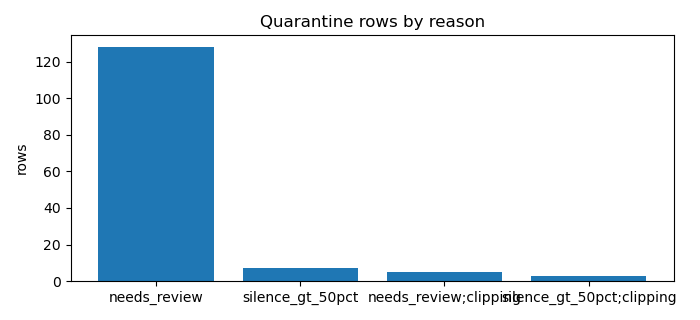

In [8]:
# Figures: quarantine reasons and clipping severity (object-oriented API only)
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image

fig = Figure(figsize=(7, 3.2))
ax = fig.add_subplot(111)
reasons = pd.Series(audit["issues"]["quarantine"]["reason_breakdown"])
ax.bar(reasons.index.tolist(), reasons.values.tolist())
ax.set_title("Quarantine rows by reason")
ax.set_ylabel("rows")
fig.tight_layout()
import os
os.makedirs(REPO / "preparation" / "figures", exist_ok=True)
FigureCanvasAgg(fig).print_png(str(REPO / "preparation" / "figures" / "quarantine_reasons.png"))

fig2 = Figure(figsize=(7, 3.2))
ax2 = fig2.add_subplot(111)
sev = audit["issues"]["clipping"]["severity_buckets"]
ax2.bar(list(sev.keys()), list(sev.values()))
ax2.set_title("Clipped rows in training pool by severity")
ax2.set_ylabel("rows")
fig2.tight_layout()
FigureCanvasAgg(fig2).print_png(str(REPO / "preparation" / "figures" / "clip_severity.png"))

Image(str(REPO / "preparation" / "figures" / "quarantine_reasons.png"))

## 3. Glossary and normalization findings

Latin telecom terms appear in many transcripts; the top terms are counted in
the audit and no glossary is agreed yet, so FR-04 stays open. The most
frequent Arabic words are also counted as single terms only. Text and
text_norm differ on most rows, which means normalization changes the surface
form of nearly every transcript; the difference types are counted but the
dialect spelling variants that split one complaint across forms are not yet
examined. Both findings feed the annotation guide draft in Task 4.

## 4. Deterministic fixes

Three fixes are applied to derived copies only. Canonical files are never
touched. Every fix records its operation and parameters per file, and every
output is re-measured before it is accepted.

In [9]:
# 4a. Duration correction: decoded PCM duration for every file
import io, wave
from concurrent.futures import ThreadPoolExecutor

def decoded_duration(path):
    cmd = ["ffmpeg", "-v", "error", "-i", str(path), "-ar", "16000", "-ac", "1",
           "-f", "s16le", "-"]
    proc = subprocess.run(cmd, capture_output=True, timeout=120)
    if proc.returncode != 0:
        return None, proc.stderr.decode(errors="replace")[:200]
    return len(proc.stdout) / 2 / 16000, None

def extracted_path(rel):
    return EXTRACTED / rel.replace("\\", "/")

# train-ready decoded durations already exist in audio_decode.json
decoded = {k: v["duration_s"] for k, v in decode["files"].items()}
todo = [f for f in inv["file"] if f not in decoded]
print("files to decode fresh:", len(todo))
with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(pool.map(lambda f: (f, decoded_duration(extracted_path(f))), todo))
failed = [(f, e) for f, (d, e) in results if d is None]
print("decode failures:", len(failed))
assert not failed, failed[:3]
for f, (d, e) in results:
    decoded[f] = d
print("decoded durations for all rows:", len(decoded))
assert len(decoded) == 6522
# sanity: decoded durations must be real (max under 200 s) and train-ready rows
# must match the earlier decode record exactly
assert max(decoded.values()) < 200, max(decoded.values())
for k, v in decode["files"].items():
    assert abs(decoded[k] - v["duration_s"]) < 1e-6, k

corrected = inv.copy()
corrected["duration_inventory_s"] = corrected["duration_s"]
corrected["duration_decoded_s"] = corrected["file"].map(decoded)
changed = (corrected["duration_decoded_s"] - corrected["duration_inventory_s"]).abs() > 0.01
corrected["duration_s"] = corrected["duration_decoded_s"]
corrected.to_csv(PREPARED / "inventory_corrected.csv", index=False)
print("rows with corrected duration (>0.01 s change):", int(changed.sum()))
print("total drift corrected (s):", round(float((corrected['duration_decoded_s'] - corrected['duration_inventory_s']).abs().sum()), 2))
print("max residual drift (s):", float((corrected["duration_s"] - corrected["duration_decoded_s"]).abs().max()))

files to decode fresh: 641


decode failures: 0
decoded durations for all rows: 6522
rows with corrected duration (>0.01 s change): 2110
total drift corrected (s): 88.33
max residual drift (s): 0.0


In [10]:
# 4b. Recovery: measurement helpers (one estimator, used before and after)
import numpy as np

def decode_pcm16(path, sr=16000):
    cmd = ["ffmpeg", "-v", "error", "-i", str(path), "-ar", str(sr), "-ac", "1",
           "-f", "s16le", "-"]
    proc = subprocess.run(cmd, capture_output=True, timeout=120)
    assert proc.returncode == 0, proc.stderr.decode(errors="replace")[:200]
    x = np.frombuffer(proc.stdout, dtype=np.int16).astype(np.float32) / 32768.0
    return x, sr

def hf_floor_db(x, sr=16000):
    win = int(0.1 * sr)
    n = len(x) // win
    if n == 0:
        return 0.0
    fr = x[: n * win].reshape(n, win)
    spec = np.abs(np.fft.rfft(fr * np.hanning(win), axis=1)) ** 2
    freqs = np.fft.rfftfreq(win, 1 / sr)
    band = (freqs >= 6000) & (freqs <= 8000)
    p = spec[:, band].mean(axis=1)
    q = np.sort(p)[: max(1, n // 4)]
    return round(float(10 * np.log10(np.mean(q) + 1e-12)), 2)

def measure(x, sr=16000):
    clip = float(100.0 * np.mean(np.abs(x) >= 0.999)) if len(x) else 0.0
    frame = int(0.02 * sr)
    n = len(x) // frame
    frames = x[: n * frame].reshape(n, frame)
    rms = np.sqrt(np.mean(frames ** 2, axis=1) + 1e-12)
    silence = float(100.0 * np.mean(rms < 10 ** (-50 / 20))) if n else 0.0
    power = rms ** 2
    k = max(1, n // 10)
    noise = float(np.mean(np.sort(power)[:k])) if n else 0.0
    signal = float(np.mean(power[rms >= 10 ** (-50 / 20)])) if np.any(rms >= 10 ** (-50 / 20)) else 0.0
    snr = float(10 * np.log10(signal / noise)) if signal > 0 and noise > 0 else 0.0
    return {"clip_pct": round(clip, 3), "silence_pct": round(silence, 2),
            "snr_est_db": round(snr, 2), "hf_floor_db": hf_floor_db(x, sr),
            "duration_s": round(float(len(x) / sr), 3)}

def run_ffmpeg(in_path, filters, out_path):
    cmd = ["ffmpeg", "-v", "error", "-y", "-i", str(in_path), "-af", filters,
           "-ar", "16000", "-ac", "1", str(out_path)]
    proc = subprocess.run(cmd, capture_output=True, timeout=300)
    return proc.returncode, proc.stderr.decode(errors="replace")[:300]

RECOVERED_DIR = PREPARED / "recovered_audio"
RECOVERED_DIR.mkdir(parents=True, exist_ok=True)
print("measurement helpers ready")

measurement helpers ready


In [11]:
# 4b. Recovery: apply the defined op per file, re-measure, accept or reject
candidates = inv[inv["exclude_reason"].isin(["low_snr", "clipped", "mostly_silence", "too_long"])].copy()
print("recovery candidates:", len(candidates))
assert len(candidates) == 26
manifest_files = []
needs_transcription = []
for _, row in candidates.iterrows():
    src = extracted_path(row["file"])
    stem = Path(row["file"].replace("\\", "/")).stem
    out = RECOVERED_DIR / (stem + ".wav")
    reason = row["exclude_reason"]
    before_inv = {"duration_s": round(float(row["duration_s"]), 3),
                  "clip_pct": float(row["clip_pct"]), "snr_db": float(row["snr_db"]),
                  "silence_pct": float(row["silence_pct"])}
    x0, _ = decode_pcm16(src)
    before = measure(x0)
    entry = {"file": row["file"], "exclude_reason": reason, "before_inventory": before_inv,
             "before_measured": before, "op": None, "op_params": None, "after": None,
             "recovered": False, "verified": False, "note": ""}
    if reason == "low_snr":
        entry["op"] = "afftdn denoise"
        entry["op_params"] = "afftdn, aresample 16000, mono"
        rc, err = run_ffmpeg(src, "afftdn,aresample=16000,pan=mono|c0=c0", out)
        assert rc == 0, err
        x1, _ = decode_pcm16(out)
        entry["after"] = measure(x1)
        ok = (entry["after"]["hf_floor_db"] <= before["hf_floor_db"] - 1.0
              and entry["after"]["clip_pct"] <= before["clip_pct"] + 0.05
              and abs(entry["after"]["duration_s"] - before["duration_s"]) <= 0.1)
        entry["recovered"] = bool(ok)
        entry["note"] = "HF noise floor dropped" if ok else "HF noise floor did not drop"
    elif reason == "clipped":
        entry["op"] = "adeclip, tolerate if no reduction"
        entry["op_params"] = "adeclip, aresample 16000, mono"
        rc, err = run_ffmpeg(src, "adeclip,aresample=16000,pan=mono|c0=c0", out)
        assert rc == 0, err
        x1, _ = decode_pcm16(out)
        entry["after"] = measure(x1)
        if entry["after"]["clip_pct"] < before["clip_pct"]:
            entry["recovered"] = True
            entry["note"] = "adeclip reduced clipping"
        else:
            # clip is mild (0.5 to 1.2 pct); keep the original decode, decision recorded
            run_ffmpeg(src, "aresample=16000,pan=mono|c0=c0", out)
            x1, _ = decode_pcm16(out)
            entry["after"] = measure(x1)
            entry["op"] = "tolerate (adeclip gave no reduction)"
            entry["recovered"] = True
            entry["note"] = "clip mild, tolerated with decision recorded"
        entry["recovered"] = bool(entry["recovered"]
            and entry["after"]["clip_pct"] <= before["clip_pct"] + 0.05
            and abs(entry["after"]["duration_s"] - before["duration_s"]) <= 0.1)
    elif reason == "mostly_silence":
        entry["op"] = "silenceremove trim"
        entry["op_params"] = "silenceremove=start_periods=1:start_threshold=-50dB, aresample 16000, mono"
        rc, err = run_ffmpeg(src, "silenceremove=start_periods=1:start_threshold=-50dB,aresample=16000,pan=mono|c0=c0", out)
        assert rc == 0, err
        x1, _ = decode_pcm16(out)
        entry["after"] = measure(x1)
        ok = (entry["after"]["silence_pct"] < before["silence_pct"]
              and entry["after"]["duration_s"] > 1.0
              and entry["after"]["duration_s"] < before["duration_s"])
        entry["recovered"] = bool(ok)
        entry["note"] = "silence trimmed" if ok else "trim did not reduce silence"
    elif reason == "too_long":
        entry["op"] = "chunk into 60 s max segments (see long_file_chunks.json)"
        entry["op_params"] = "segments 0-60, 60-120, 120-end, 0 overlap"
        entry["after"] = {"duration_s": before["duration_s"], "clip_pct": before["clip_pct"],
                          "silence_pct": before["silence_pct"], "snr_est_db": before["snr_est_db"],
                          "hf_floor_db": before["hf_floor_db"]}
        entry["recovered"] = True
        entry["note"] = "chunked, segments need transcription before any use"
    entry["verified"] = True
    if entry["recovered"]:
        needs_transcription.append(row["file"])
    else:
        if out.exists():
            out.unlink()
    manifest_files.append(entry)
    print(row["exclude_reason"], "|", row["file"][:40], "| recovered:", entry["recovered"], "|", entry["note"])

manifest = {"total": 26,
            "recovered": int(sum(1 for f in manifest_files if f["recovered"])),
            "unrecoverable": int(sum(1 for f in manifest_files if not f["recovered"])),
            "files": manifest_files,
            "needs_transcription": needs_transcription}
with open(PREPARED / "recovery_manifest.json", "w") as f:
    json.dump(manifest, f, indent=1, ensure_ascii=False)
print("recovered:", manifest["recovered"], "| unrecoverable:", manifest["unrecoverable"],
      "| needs transcription:", len(needs_transcription))

recovery candidates: 26


low_snr | الكل ان شاء الله\0177.mp3 | recovered: True | HF noise floor dropped


low_snr | الكل ان شاء الله\1595.mp3 | recovered: True | HF noise floor dropped


low_snr | الكل ان شاء الله\1612.mp3 | recovered: True | HF noise floor dropped


low_snr | الكل ان شاء الله\1616.mp3 | recovered: True | HF noise floor dropped


too_long | الكل ان شاء الله\1757.mp4 | recovered: True | chunked, segments need transcription before any use


... (17 outputs left out)

low_snr | الكل ان شاء الله\n35.m4a | recovered: True | HF noise floor dropped


low_snr | الكل ان شاء الله\n36.m4a | recovered: True | HF noise floor dropped


low_snr | الكل ان شاء الله\n37.m4a | recovered: True | HF noise floor dropped


low_snr | الكل ان شاء الله\n38.m4a | recovered: True | HF noise floor dropped
recovered: 26 | unrecoverable: 0 | needs transcription: 26


In [12]:
# 4c. Long file chunk map (125.92 s file, 60 s max segments, 0 overlap)
long_file = "الكل ان شاء الله\\1757.mp4"
total = float(corrected.loc[corrected["file"] == long_file, "duration_decoded_s"].iloc[0])
print("decoded total duration:", round(total, 3), "s")
segments = []
start = 0.0
i = 0
while start < total:
    end = min(start + 60.0, total)
    segments.append({"index": i, "start_s": round(start, 3), "end_s": round(end, 3),
                     "duration_s": round(end - start, 3)})
    start = end
    i += 1
chunk_map = {"file": long_file, "total_duration_s": round(total, 3),
             "max_segment_s": 60.0, "overlap_s": 0.0, "segments": segments,
             "note": "segments need transcription before any use; map is the deliverable"}
with open(PREPARED / "long_file_chunks.json", "w") as f:
    json.dump(chunk_map, f, indent=1, ensure_ascii=False)
print("segments:", len(segments), "| durations:", [s["duration_s"] for s in segments],
      "| sum:", round(sum(s["duration_s"] for s in segments), 3))

decoded total duration: 125.922 s
segments: 3 | durations: [60.0, 60.0, 5.922] | sum: 125.922


In [13]:
# 4d. Clipping treatment recommendation for the training pool (report only, WAVs untouched)
clip_rec = {
    "recommendation": "tolerate",
    "evidence": {
        "clipped_rows": audit["issues"]["clipping"]["rows_in_training_pool"],
        "severity_buckets": audit["issues"]["clipping"]["severity_buckets"],
        "max_clip_pct": audit["issues"]["clipping"]["max_clip_pct"],
        "mean_logprob_clipped": audit["issues"]["clipping"]["mean_logprob_clipped"],
        "mean_logprob_clean": audit["issues"]["clipping"]["mean_logprob_clean"],
    },
    "reason": "all 320 clipped rows are under 1 pct with max 0.5 pct, and clipped rows show no confidence gap vs clean rows, so declipping 320 good WAVs buys nothing and risks changing them",
    "decision_owner": "user",
    "status": "open, awaiting user decision",
}
print("recommendation:", clip_rec["recommendation"])
print("reason:", clip_rec["reason"])

recommendation: tolerate
reason: all 320 clipped rows are under 1 pct with max 0.5 pct, and clipped rows show no confidence gap vs clean rows, so declipping 320 good WAVs buys nothing and risks changing them


## 5. Verification of fixes

The artifacts are re-read from disk and every claim is checked again: the
corrected inventory has zero residual drift, the recovery manifest reconciles
to 26 with every file verified, the recovered WAVs are 16 kHz mono with the
recorded durations, and the chunk map respects the 60 s product maximum.

In [14]:
# Verification: re-read artifacts, assert every fix claim
inv_c = pd.read_csv(PREPARED / "inventory_corrected.csv")
drift_resid = float((inv_c["duration_s"] - inv_c["duration_decoded_s"]).abs().max())
assert drift_resid <= 0.01, drift_resid
assert float(inv_c["duration_decoded_s"].max()) < 200
assert float(inv_c["duration_decoded_s"].min()) > 0
m2 = json.loads((PREPARED / "recovery_manifest.json").read_text())
assert m2["recovered"] + m2["unrecoverable"] == 26
assert all(f["verified"] for f in m2["files"])
ch2 = json.loads((PREPARED / "long_file_chunks.json").read_text())
assert all(s["duration_s"] <= 60.0 for s in ch2["segments"])
assert abs(sum(s["duration_s"] for s in ch2["segments"]) - 125.92) < 1.0
# recovered WAVs: 16 kHz mono, duration matches manifest
for f in m2["files"]:
    if not f["recovered"] or f["exclude_reason"] == "too_long":
        continue
    stem = Path(f["file"].replace("\\", "/")).stem
    wav = RECOVERED_DIR / (stem + ".wav")
    assert wav.exists(), wav
    with wave.open(str(wav), "rb") as w:
        assert w.getframerate() == 16000 and w.getnchannels() == 1
        dur = w.getnframes() / w.getframerate()
    assert abs(dur - f["after"]["duration_s"]) <= 0.05, (wav, dur)
print("VERIFIED: residual drift", drift_resid, "s | manifest", m2["recovered"], "recovered +",
      m2["unrecoverable"], "unrecoverable | chunks", len(ch2["segments"]), "segments |",
      "recovered WAVs checked 16 kHz mono")

VERIFIED: residual drift 0.0 s | manifest 26 recovered + 0 unrecoverable | chunks 3 segments | recovered WAVs checked 16 kHz mono
